# EDA and audit



In [1]:
#the project paths get printed here 
#عشان تشوفو شكلها

from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, UnidentifiedImageError
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
DATASETS = ROOT / "datasets"
RAW_CSV = DATASETS / "train.csv"
RAW_IMAGES = DATASETS / "train_images"
PROCESSED = DATASETS / "aptos_512_clahe_balanced"
GRAPH_DIR = ROOT / "artefacts"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative DR"}
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

assert RAW_CSV.exists(), f"Missing {RAW_CSV}"
assert RAW_IMAGES.is_dir(), f"Missing {RAW_IMAGES}"
assert PROCESSED.is_dir(), f"Missing {PROCESSED}"
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
print("Project root:", ROOT)
print("Raw images:", RAW_IMAGES)
print("Processed dataset:", PROCESSED)
print("Graph output folder:", GRAPH_DIR)

def save_figure(fig, filename):
    """Save one notebook graph as a standalone PNG in artefacts/."""
    output_path = GRAPH_DIR / filename
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    print("Saved graph:", output_path)
    return output_path


Project root: d:\omar\SIC\grad_project
Raw images: d:\omar\SIC\grad_project\datasets\train_images
Processed dataset: d:\omar\SIC\grad_project\datasets\aptos_512_clahe_balanced
Graph output folder: d:\omar\SIC\grad_project\artefacts


## EDA on the unprocessed training dataset



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3662 entries, 0 to 3661
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id_code    3662 non-null   object
 1   diagnosis  3662 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 57.3+ KB


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_code,3662,3662,ffec9a18a3ce,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diagnosis,3662.0,NaN,NaN,NaN,1.12698,1.298409,0.0,0.0,1.0,2.0,4.0


Rows: 3662
Missing values:
 id_code      0
diagnosis    0
dtype: int64
Duplicate IDs: 0
Invalid/missing grades: 0


,count,percent
diagnosis,,
No DR,1805,49.290005
Mild,370,10.103768
Moderate,999,27.280175
Severe,193,5.270344
Proliferative DR,295,8.055707


Saved graph: d:\omar\SIC\grad_project\artefacts\raw_class_balance.png


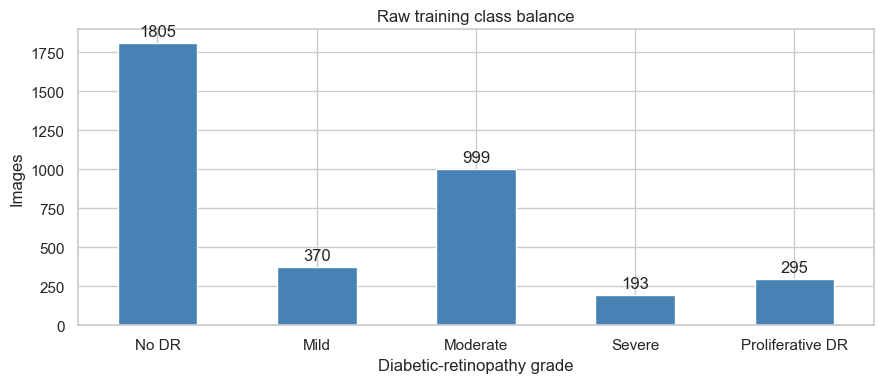

In [2]:
raw = pd.read_csv(RAW_CSV)
raw.info()
display(raw.head())
display(raw.describe(include="all").T)

required = {"id_code", "diagnosis"}
assert required.issubset(raw.columns), f"Expected {required}; found {set(raw.columns)}"
raw["id_code"] = raw["id_code"].astype("string").str.strip()
raw["diagnosis"] = pd.to_numeric(raw["diagnosis"], errors="coerce")
print("Rows:", len(raw))
print("Missing values:\n", raw.isna().sum())
print("Duplicate IDs:", raw["id_code"].duplicated().sum())
print("Invalid/missing grades:", (~raw["diagnosis"].isin(range(5))).sum())
raw_counts = raw["diagnosis"].value_counts().reindex(range(5), fill_value=0)
raw_summary = pd.DataFrame({"count": raw_counts, "percent": raw_counts / len(raw) * 100})
raw_summary.index.name = "diagnosis"
display(raw_summary.rename(index=CLASS_NAMES))
fig, ax = plt.subplots(figsize=(9, 4))
raw_counts.rename(index=CLASS_NAMES).plot.bar(ax=ax, color="steelblue")
ax.set(title="Raw training class balance", xlabel="Diabetic-retinopathy grade", ylabel="Images")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
plt.xticks(rotation=0); plt.tight_layout()
save_figure(fig, "raw_class_balance.png")
plt.show()


### Raw image readability, dimensions,and file sizes

In [3]:
image_map = {}
for p in RAW_IMAGES.iterdir():
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
        image_map.setdefault(p.stem, []).append(p)

records = []
for row in raw.itertuples(index=False):
    image_id = str(row.id_code)
    matches = image_map.get(image_id, [])
    rec = {"id_code": image_id, "diagnosis": int(row.diagnosis) if pd.notna(row.diagnosis) else np.nan,
           "match_count": len(matches), "readable": False}
    if len(matches) == 1:
        path = matches[0]
        rec["file_bytes"] = path.stat().st_size
        try:
            with Image.open(path) as im:
                im.load()
                rec.update(width=im.width, height=im.height, mode=im.mode, format=im.format, readable=True)
        except (OSError, ValueError, UnidentifiedImageError):
            pass
    records.append(rec)
raw_img = pd.DataFrame(records)
extra_ids = sorted(set(image_map) - set(raw.id_code.dropna().astype(str)))
print("Image files:", sum(map(len, image_map.values())))
print("CSV IDs with no file:", int((raw_img.match_count == 0).sum()))
print("CSV IDs with multiple matching files:", int((raw_img.match_count > 1).sum()))
print("Unreadable images:", int((~raw_img.readable).sum()))
print("Unreferenced image IDs:", len(extra_ids))
display(raw_img.groupby("diagnosis")[ ["width", "height", "file_bytes"] ].describe().round(1))
display(raw_img["mode"].value_counts(dropna=False).rename("count").to_frame())
display(raw_img[["width", "height"]].value_counts(dropna=False).head(20).rename("count").to_frame())


Image files: 3662
CSV IDs with no file: 0
CSV IDs with multiple matching files: 0
Unreadable images: 0
Unreferenced image IDs: 0


width                                                        \
            count    mean    std    min     25%     50%     75%     max   
diagnosis                                                                 
0          1805.0  1433.4  629.4  819.0  1050.0  1050.0  2048.0  3216.0   
1           370.0  2471.4  625.8  819.0  2416.0  2416.0  2588.0  4288.0   
2           999.0  2603.9  735.2  474.0  2416.0  2588.0  3216.0  4288.0   
3           193.0  2590.7  603.3  640.0  2416.0  2588.0  2896.0  4288.0   
4           295.0  2632.3  791.0  474.0  2416.0  2588.0  3216.0  4288.0   

           height                                                        \
            count    mean    std    min     25%     50%     75%     max   
diagnosis                                                                 
0          1805.0  1206.7  407.2  614.0  1050.0  1050.0  1536.0  2136.0   
1           370.0  1784.7  395.2  614.0  1736.0  1736.0  1944.0  2848.0   
2           999.0  1846.5  493.2  358.0  1736.0  1958.0  2136.0  2848.0   
3           193.0  1840.8  398.9  480.0  1736.0  1944.0  1958.0  2848.0   
4           295.0  1874.5  527.2  358.0  1736.0  1958.0  2136.0  2848.0   

          file_bytes                                                        \
               count       mean        std       min        25%        50%   
diagnosis                                                                    
0             1805.0  1624913.0  1479353.0  258426.0   935808.0  1025378.0   
1              370.0  2564463.6  1331228.8  309635.0  1988522.5  2192263.0   
2              999.0  3133485.3  1788440.1  234100.0  2089369.5  2546361.0   
3              193.0  3133151.6  1531809.9  314473.0  2092808.0  2451030.0   
4              295.0  3343034.5  1968141.0  221737.0  2093061.5  2547255.0   

                                 
                 75%        max  
diagnosis                        
0          1911983.0  5937607.0  
1          2496490.5  7261377.0  
2          4772572.5  7674292.0  
3          4824757.0  7448084.0  
4          5190214.5  7549287.0

,count
mode,
RGB,3662


,,count
width,height,
1050,1050,974
2416,1736,638
2588,1958,533
3216,2136,410
2048,1536,351
819,614,287
3388,2588,141
1504,1000,92
1844,1226,61


###  Raw image visual-quality statistics  (brightness and std)



,count,mean,std,min,25%,50%,75%,max
diagnosis,3662.0,1.1270,1.2984,0.0000,0.0000,1.0000,2.0000,4.0000
width,3662.0,2015.1767,884.3019,474.0000,1050.0000,2144.0000,2588.0000,4288.0000
height,3662.0,1526.8301,542.6631,358.0000,1050.0000,1536.0000,1958.0000,2848.0000
aspect_ratio,3662.0,1.2838,0.1821,1.0000,1.0000,1.3333,1.3917,1.5056
brightness_mean,3662.0,0.3412,0.0811,0.1080,0.2858,0.3546,0.3995,0.6055
brightness_std,3662.0,0.0722,0.0226,0.0238,0.0574,0.0680,0.0809,0.2189
brightness_p05,3662.0,0.2500,0.0963,0.0348,0.1853,0.2688,0.3207,0.5649
brightness_p95,3662.0,0.4449,0.0935,0.1433,0.3802,0.4560,0.5095,0.8129
saturation_mean,3662.0,0.4501,0.1625,0.0308,0.3607,0.4860,0.5708,0.7931
edge_density,3662.0,0.0176,0.0071,0.0000,0.0131,0.0175,0.0203,0.0553


,width,height,aspect_ratio,brightness_mean,brightness_std,brightness_p05,brightness_p95,saturation_mean,edge_density
diagnosis,,,,,,,,,
0,1433.4155,1206.6748,1.1667,0.3501,0.0784,0.2550,0.4630,0.4605,0.0202
1,2471.4459,1784.6649,1.3753,0.3287,0.0636,0.2418,0.4191,0.4751,0.0136
2,2603.8769,1846.4625,1.4044,0.3386,0.0655,0.2547,0.4318,0.4395,0.0152
3,2590.7461,1840.8187,1.4044,0.3181,0.0731,0.2202,0.4253,0.4013,0.0174
4,2632.3390,1874.5220,1.3985,0.3262,0.0674,0.2332,0.4242,0.4234,0.0145


Saved graph: d:\omar\SIC\grad_project\artefacts\raw_image_metric_distributions.png


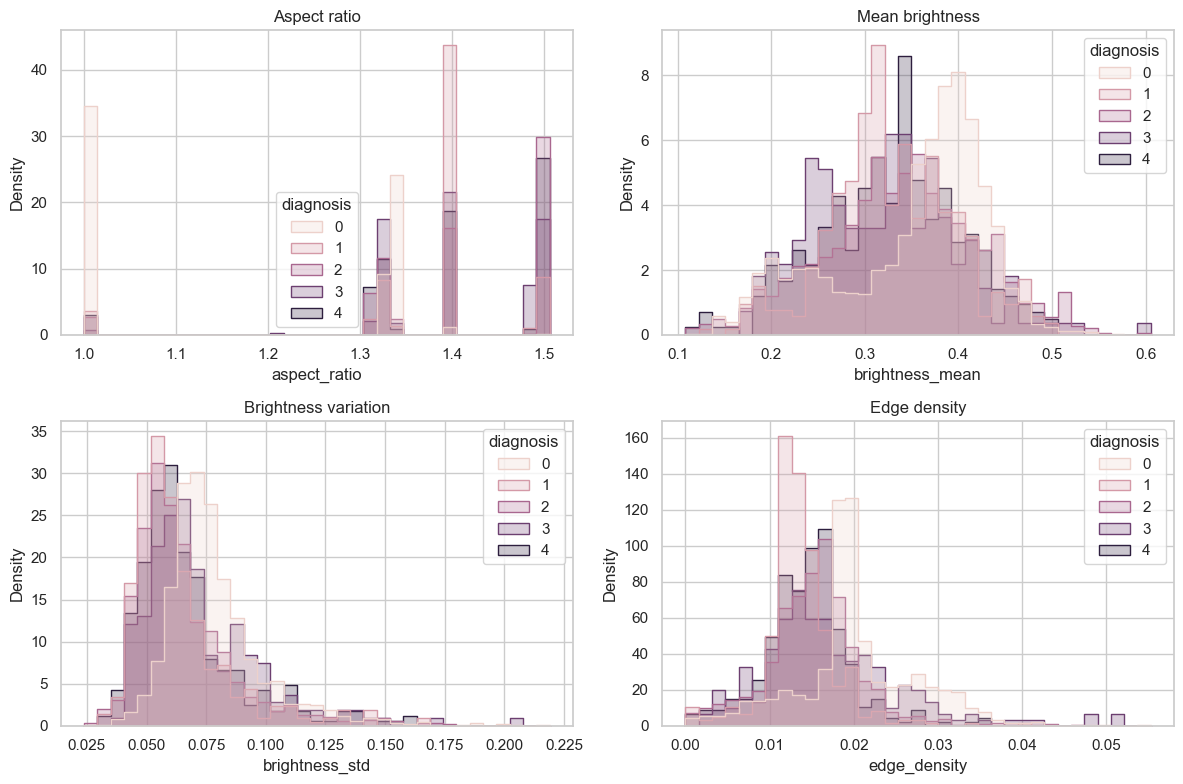

Saved graph: d:\omar\SIC\grad_project\artefacts\raw_top_image_dimensions.png


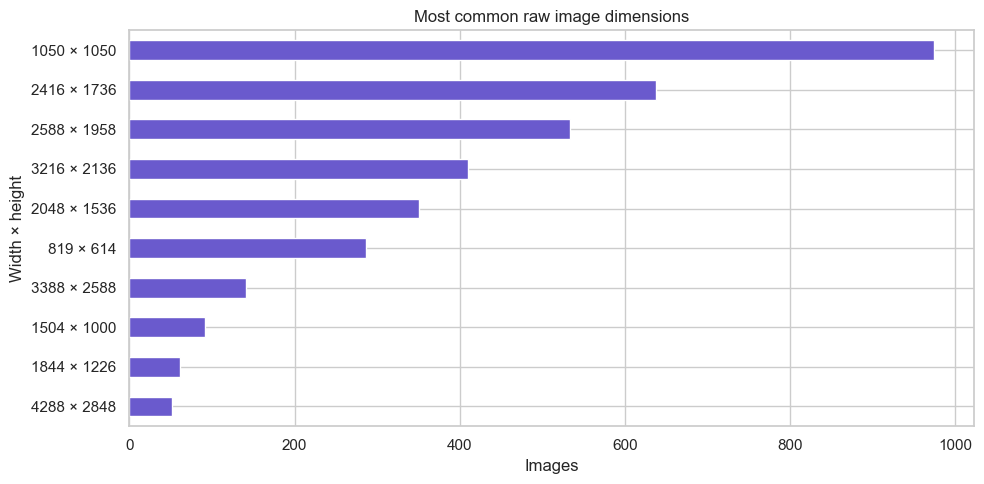

In [4]:
def image_metrics(path, analysis_size=(256, 256)):
    """Summarize image content after the same aspect-preserving square fit.

    A simple luminance mask excludes black canvas/padding from color and texture
    summaries so source and processed measurements are more comparable.
    """
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        original_w, original_h = im.size
        small = ImageOps.pad(
            im, analysis_size, method=Image.Resampling.BILINEAR,
            color=(0, 0, 0), centering=(0.5, 0.5)
        )
        rgb = np.asarray(small, dtype=np.float32) / 255.0
    gray = 0.299*rgb[:,:,0] + 0.587*rgb[:,:,1] + 0.114*rgb[:,:,2]
    roi = gray > (8 / 255.0)
    if roi.sum() < 100:
        roi = np.ones_like(gray, dtype=bool)
    gx = np.diff(gray, axis=1); gy = np.diff(gray, axis=0)
    grad = np.sqrt(gx[:-1,:]**2 + gy[:,:-1]**2)
    edge_roi = roi[:-1, :-1] & roi[1:, 1:]
    pixels = rgb[roi]
    gray_pixels = gray[roi]
    return {"width": original_w, "height": original_h, "aspect_ratio": original_w/original_h,
            "brightness_mean": float(gray_pixels.mean()), "brightness_std": float(gray_pixels.std()),
            "brightness_p05": float(np.quantile(gray_pixels, .05)), "brightness_p95": float(np.quantile(gray_pixels, .95)),
            "saturation_mean": float((pixels.max(axis=1)-pixels.min(axis=1)).mean()),
            "edge_density": float(((grad > .08) & edge_roi).sum() / max(edge_roi.sum(), 1))}

metric_rows = []
for rec in raw_img.loc[raw_img.match_count.eq(1) & raw_img.readable].itertuples(index=False):
    vals = image_metrics(image_map[rec.id_code][0])
    metric_rows.append({"id_code":rec.id_code, "diagnosis":rec.diagnosis, **vals})
raw_metrics = pd.DataFrame(metric_rows)
display(raw_metrics.drop(columns="id_code").describe().T.round(4))
display(raw_metrics.groupby("diagnosis").mean(numeric_only=True).round(4))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col, title in zip(axes.flat,
        ["aspect_ratio", "brightness_mean", "brightness_std", "edge_density"],
        ["Aspect ratio", "Mean brightness", "Brightness variation", "Edge density"]):
    sns.histplot(data=raw_metrics, x=col, hue="diagnosis", bins=35, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
save_figure(fig, "raw_image_metric_distributions.png")
plt.show()

# Most common source resolutions help explain why a consistent input size is needed.
dimension_counts = (
    raw_img.groupby(["width", "height"], dropna=False)
    .size()
    .nlargest(10)
    .sort_values()
)
dimension_counts.index = [
    f"{int(width)} × {int(height)}" for width, height in dimension_counts.index
]
fig, ax = plt.subplots(figsize=(10, 5))
dimension_counts.plot.barh(ax=ax, color="slateblue")
ax.set(title="Most common raw image dimensions", xlabel="Images", ylabel="Width × height")
plt.tight_layout()
save_figure(fig, "raw_top_image_dimensions.png")
plt.show()


## Before-versus-after preprocessing EDA



###  Processed split and class balance

train: 6,315 label rows; columns=['id_code', 'diagnosis', 'is_augmented', 'split']
validation: 550 label rows; columns=['id_code', 'diagnosis', 'split']
test: 550 label rows; columns=['id_code', 'diagnosis', 'split']


,No DR,Mild,Moderate,Severe,Proliferative DR
split,,,,,
train,1263,1263,1263,1263,1263
validation,271,56,150,29,44
test,271,56,150,29,44


Leakage check passed: original train, validation, and test IDs are disjoint.
All raw image IDs are represented exactly once across the original splits.
Augmented training rows: 3,753
Saved graph: d:\omar\SIC\grad_project\artefacts\processed_class_balance_by_split.png


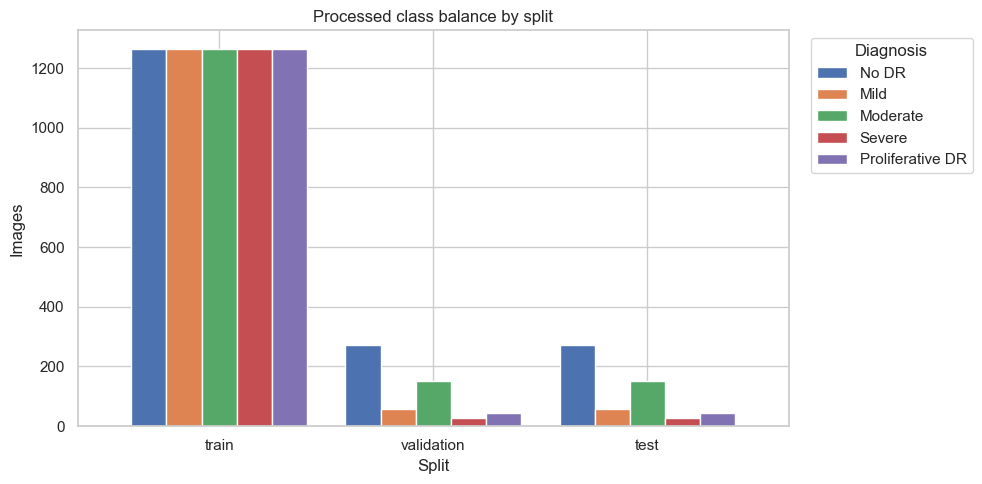

In [5]:
#Load processed labels for each split
split_frames = {}

for split in ["train", "validation", "test"]:
    label_path = PROCESSED / split / "labels.csv"

    if label_path.exists():
        frame = pd.read_csv(label_path)
        frame["split"] = split
        split_frames[split] = frame
        print(f"{split}: {len(frame):,} label rows; columns={list(frame.columns)}")

# Check that all three expected splits were loaded
required_splits = {"train", "validation", "test"}
assert required_splits.issubset(split_frames), (
    f"Missing split labels: {required_splits - set(split_frames)}"
)

# Show processed class counts
processed_labels = pd.concat(split_frames.values(), ignore_index=True)

count_table = (
    pd.crosstab(processed_labels["split"], processed_labels["diagnosis"])
    .reindex(index=["train", "validation", "test"], columns=range(5), fill_value=0)
)
count_table.columns = [CLASS_NAMES[grade] for grade in count_table.columns]
display(count_table)

# Check leakage among original images.
train_df = split_frames["train"]
val_df = split_frames["validation"]
test_df = split_frames["test"]

assert "is_augmented" in train_df.columns, (
    "Training labels need an 'is_augmented' column to distinguish originals "
    "from augmented images."
)

augmented_mask = (
    train_df["is_augmented"]
    .astype(str)
    .str.lower()
    .isin(["true", "1", "yes"])
)

train_original_ids = set(train_df.loc[~augmented_mask, "id_code"].astype(str))
train_augmented_ids = set(train_df.loc[augmented_mask, "id_code"].astype(str))
val_ids = set(val_df["id_code"].astype(str))
test_ids = set(test_df["id_code"].astype(str))
raw_ids = set(raw["id_code"].astype(str))

assert train_original_ids.isdisjoint(val_ids), (
    "Leakage detected: original training IDs overlap validation IDs."
)
assert train_original_ids.isdisjoint(test_ids), (
    "Leakage detected: original training IDs overlap test IDs."
)
assert val_ids.isdisjoint(test_ids), (
    "Leakage detected: validation IDs overlap test IDs."
)

assigned_original_ids = train_original_ids | val_ids | test_ids
assert assigned_original_ids == raw_ids, (
    f"Original ID mismatch: {len(raw_ids - assigned_original_ids)} raw IDs "
    f"are missing from the splits, and "
    f"{len(assigned_original_ids - raw_ids)} unexpected IDs were found."
)

print("Leakage check passed: original train, validation, and test IDs are disjoint.")
print("All raw image IDs are represented exactly once across the original splits.")
print(f"Augmented training rows: {int(augmented_mask.sum()):,}")

# Plot processed class counts by split
fig, ax = plt.subplots(figsize=(10, 5))
count_table.plot(kind="bar", ax=ax, width=0.82)
ax.set(
    title="Processed class balance by split",
    xlabel="Split",
    ylabel="Images",
)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Diagnosis", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
save_figure(fig, "processed_class_balance_by_split.png")
plt.show()


### Processed  image statistics (brightness and std stats)



In [6]:
def resolve_processed_image(split, image_id):
    """Return the unique processed image path for an ID, or None if absent/ambiguous."""
    image_dir = PROCESSED / split / "images"
    matches = [image_dir / f"{image_id}{ext}" for ext in IMAGE_EXTENSIONS
               if (image_dir / f"{image_id}{ext}").is_file()]
    return matches[0] if len(matches) == 1 else None


# Verify ID/file coverage for every processed split without loading every image into memory.
for split, frame in split_frames.items():
    image_dir = PROCESSED / split / "images"
    actual_ids = {path.stem for path in image_dir.iterdir()
                  if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS}
    expected_ids = set(frame["id_code"].astype(str))
    print(f"{split}: labels={len(frame)}, files={len(actual_ids)}, "
          f"missing={len(expected_ids - actual_ids)}, unreferenced={len(actual_ids - expected_ids)}")
    if expected_ids != actual_ids:
        raise ValueError(f"Processed image IDs do not match labels for {split}.")

# Deterministic, grade-stratified sample for image-level summaries; full split counts
# remain above. Training is also stratified by original/augmented status.
MAX_PER_GROUP = 80
sampled_frames = []
for split, frame in split_frames.items():
    if split == "train" and "is_augmented" in frame:
        groups = frame.groupby(["diagnosis", "is_augmented"], dropna=False)
    else:
        groups = frame.groupby("diagnosis", dropna=False)
    for _, group in groups:
        sampled_frames.append(group.sample(n=min(MAX_PER_GROUP, len(group)), random_state=42))
metric_sample = pd.concat(sampled_frames, ignore_index=True)
print(f"Computing image metrics on a reproducible stratified sample: {len(metric_sample):,} images")

after_rows = []
for row in metric_sample.itertuples(index=False):
    split = row.split
    image_id = str(row.id_code)
    image_path = resolve_processed_image(split, image_id)
    if image_path is None:
        raise FileNotFoundError(f"Processed image missing or ambiguous: {split}/{image_id}")
    with Image.open(image_path) as im:
        im.load()
        width, height, mode = im.width, im.height, im.mode
    record = {
        "split": split,
        "id_code": image_id,
        "diagnosis": int(row.diagnosis),
        "is_augmented": bool(getattr(row, "is_augmented", False)),
        "path": image_path,
        "readable": True,
        "file_bytes": image_path.stat().st_size,
        "width": width,
        "height": height,
        "mode": mode,
    }
    record.update(image_metrics(image_path))
    after_rows.append(record)

after_metrics = pd.DataFrame(after_rows)
print("Sampled processed images:", len(after_metrics))
print("Unreadable sampled processed images:", int((~after_metrics["readable"]).sum()))
display(after_metrics.groupby("split")[["width", "height", "file_bytes", "brightness_mean", "brightness_std", "saturation_mean", "edge_density"]].agg(["count", "mean", "std", "min", "median", "max"]).round(4))
display(pd.crosstab(after_metrics["split"], after_metrics["mode"], dropna=False))
print("Sampled image dimension counts:")
display(after_metrics[["width", "height"]].value_counts(dropna=False).rename("images").to_frame())


train: labels=6315, files=6315, missing=0, unreferenced=0
validation: labels=550, files=550, missing=0, unreferenced=0
test: labels=550, files=550, missing=0, unreferenced=0
Computing image metrics on a reproducible stratified sample: 1,298 images
Sampled processed images: 1298
Unreadable sampled processed images: 0


width                              height                          \
           count   mean  std  min median  max  count   mean  std  min median   
split                                                                          
test         289  512.0  0.0  512  512.0  512    289  512.0  0.0  512  512.0   
train        720  512.0  0.0  512  512.0  512    720  512.0  0.0  512  512.0   
validation   289  512.0  0.0  512  512.0  512    289  512.0  0.0  512  512.0   

                file_bytes                                                     \
            max      count         mean         std     min    median     max   
split                                                                           
test        512        289  284861.7439  67929.7115  167226  273498.0  438653   
train       512        720  257444.1583  58390.7034  160828  247297.0  439697   
validation  512        289  298112.8028  70493.8863  168265  278032.0  450737   

           brightness_mean                                          \
                     count    mean     std     min  median     max   
split                                                                
test                   289  0.3382  0.0604  0.1912  0.3448  0.4605   
train                  720  0.3458  0.0604  0.1643  0.3504  0.5581   
validation             289  0.3359  0.0587  0.1693  0.3410  0.4958   

           brightness_std                                          \
                    count    mean     std     min  median     max   
split                                                               
test                  289  0.1247  0.0269  0.0654  0.1280  0.1915   
train                 720  0.1118  0.0278  0.0517  0.1088  0.1957   
validation            289  0.1247  0.0245  0.0654  0.1266  0.1901   

           saturation_mean                                          \
                     count    mean     std     min  median     max   
split                                                                
test                   289  0.4032  0.1373  0.0297  0.4350  0.6759   
train                  720  0.4134  0.1433  0.0402  0.4327  0.7524   
validation             289  0.4047  0.1351  0.0707  0.4258  0.7098   

           edge_density                                          
                  count    mean     std     min  median     max  
split                                                            
test                289  0.0546  0.0231  0.0046  0.0496  0.1628  
train               720  0.0526  0.0233  0.0018  0.0482  0.1670  
validation          289  0.0530  0.0234  0.0116  0.0495  0.1670

mode,RGB
split,
test,289
train,720
validation,289


Sampled image dimension counts:


,,images
width,height,
512,512,1298


### processed class and augmentation charts
light and brightness stats too

,Original,Augmented
No DR,1263,0
Mild,258,1005
Moderate,699,564
Severe,135,1128
Proliferative DR,207,1056


Saved graph: d:\omar\SIC\grad_project\artefacts\processed_train_original_vs_augmented.png


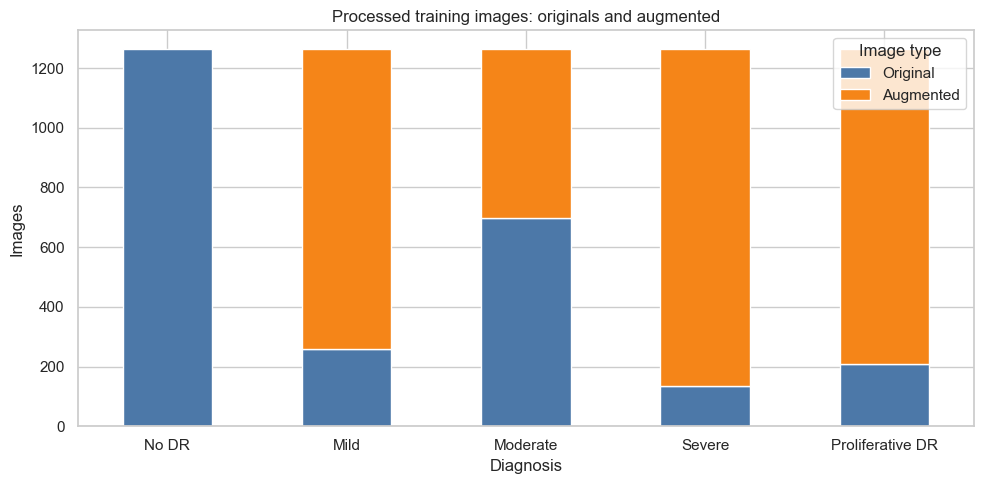

Saved graph: d:\omar\SIC\grad_project\artefacts\processed_image_metrics_by_split.png


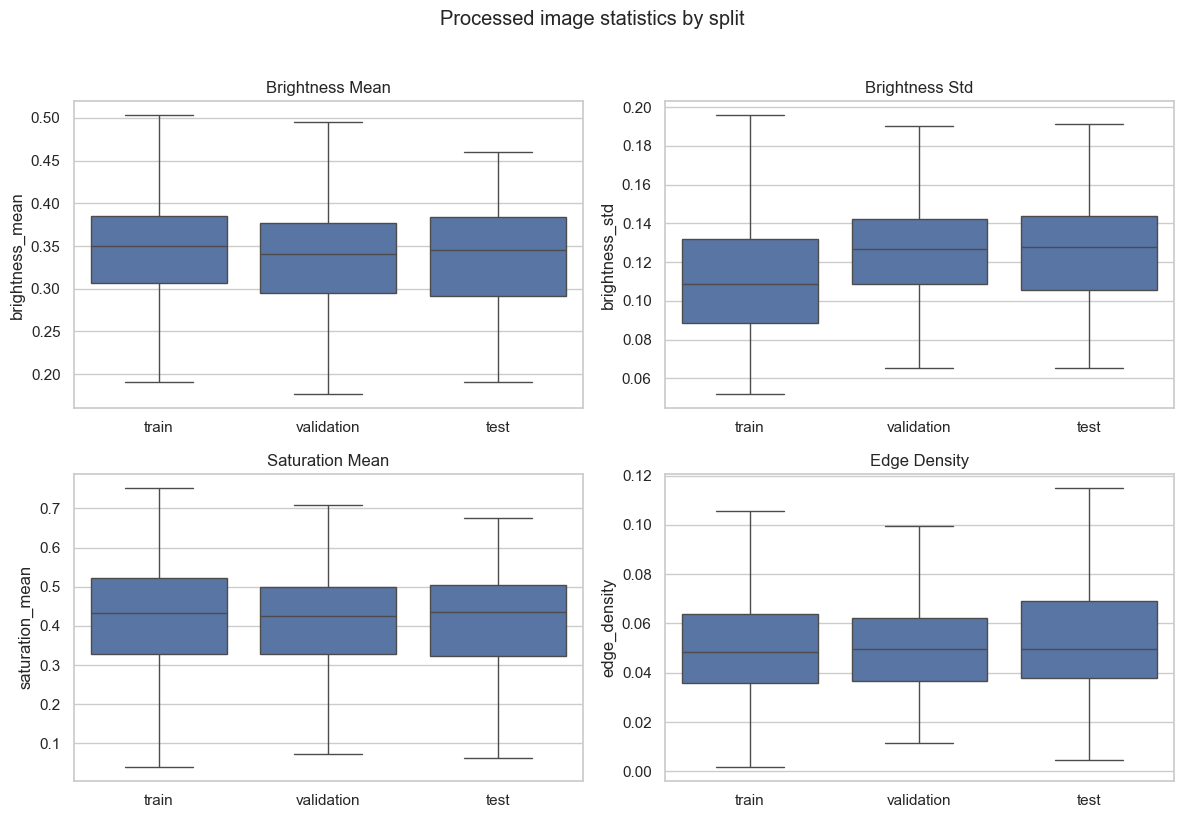

Saved graph: d:\omar\SIC\grad_project\artefacts\processed_file_sizes_by_split.png


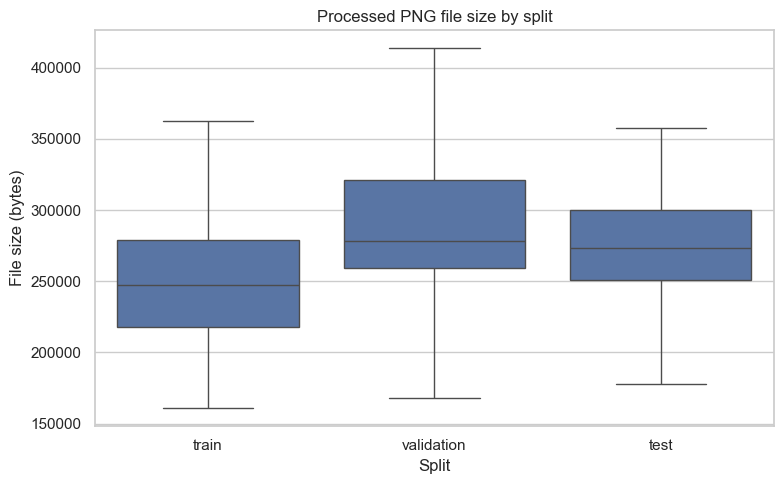

In [7]:
#Show how the balanced training set differs from the unaugmented validation/test splits.
train_labels = split_frames.get("train", pd.DataFrame()).copy()
if "is_augmented" in train_labels:
    augmentation_counts = pd.crosstab(
        train_labels["diagnosis"], train_labels["is_augmented"]
    ).reindex(index=range(5), columns=[False, True], fill_value=0)
    augmentation_counts.columns = ["Original", "Augmented"]
    augmentation_counts.index = [CLASS_NAMES[i] for i in augmentation_counts.index]
    display(augmentation_counts)
    fig, ax = plt.subplots(figsize=(10, 5))
    augmentation_counts.plot(kind="bar", stacked=True, ax=ax, color=["#4C78A8", "#F58518"])
    ax.set(title="Processed training images: originals and augmented", xlabel="Diagnosis", ylabel="Images")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Image type")
    plt.tight_layout()
    save_figure(fig, "processed_train_original_vs_augmented.png")
    plt.show()

# Image metric distributions after preprocessing, across each split.
metrics_to_plot = ["brightness_mean", "brightness_std", "saturation_mean", "edge_density"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metrics_to_plot):
    sns.boxplot(data=after_metrics, x="split", y=metric, order=["train", "validation", "test"],
                showfliers=False, ax=ax)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("")
plt.suptitle("Processed image statistics by split", y=1.02)
plt.tight_layout()
save_figure(fig, "processed_image_metrics_by_split.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=after_metrics, x="split", y="file_bytes", order=["train", "validation", "test"],
            showfliers=False, ax=ax)
ax.set(title="Processed PNG file size by split", xlabel="Split", ylabel="File size (bytes)")
plt.tight_layout()
save_figure(fig, "processed_file_sizes_by_split.png")
plt.show()


### Matched raw versus processed originals



Matched raw/processed originals: 400 of 400 non-augmented processed training images


,raw_mean,processed_mean,mean_change,change_95pct_low,change_95pct_high
brightness_mean,0.32767,0.33062,0.00295,-0.00023,0.00613
brightness_std,0.06937,0.12442,0.05505,0.05222,0.05787
brightness_p05,0.23541,0.07555,-0.15986,-0.17203,-0.14769
brightness_p95,0.42848,0.49195,0.06348,0.06068,0.06627
saturation_mean,0.43479,0.39397,-0.04082,-0.04427,-0.03737
edge_density,0.01590,0.05155,0.03565,0.03380,0.03749


Saved graph: d:\omar\SIC\grad_project\artefacts\before_after_metric_means.png


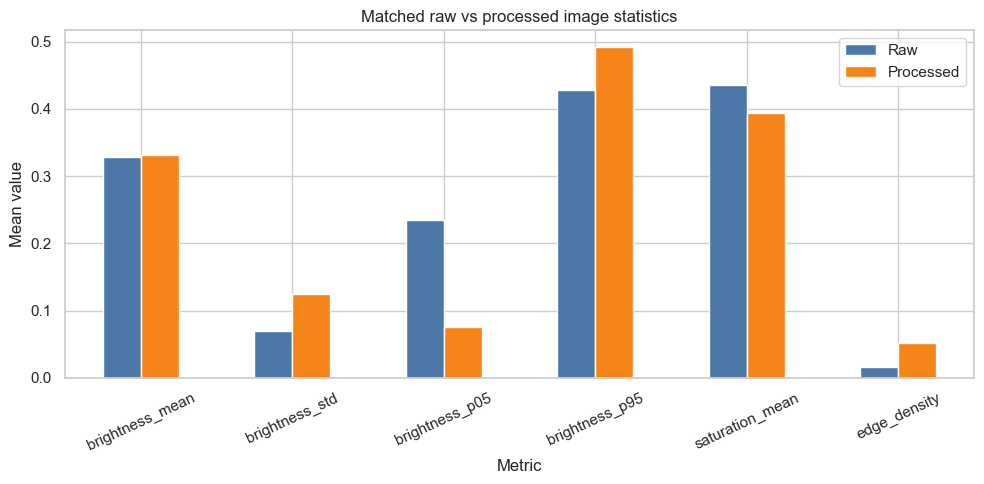

Saved graph: d:\omar\SIC\grad_project\artefacts\before_after_metric_changes.png


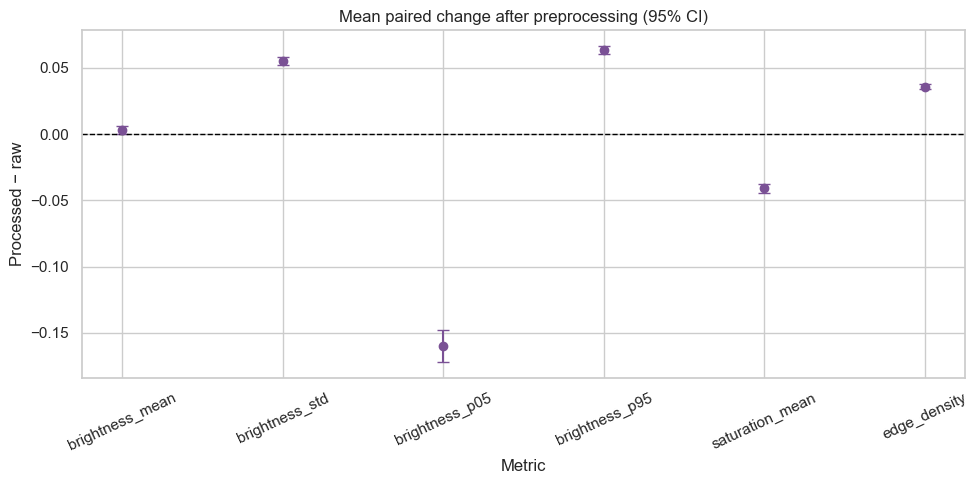

In [8]:
train_after = after_metrics[after_metrics["split"].eq("train")].copy()
if "is_augmented" in train_after:
    original_after = train_after[~train_after["is_augmented"]].copy()
else:
    original_after = train_after.copy()

metric_cols = ["brightness_mean", "brightness_std", "brightness_p05", "brightness_p95",
               "saturation_mean", "edge_density"]
before_for_join = raw_metrics.rename(columns={c: f"before_{c}" for c in raw_metrics.columns if c != "id_code"})
after_for_join = original_after[["id_code", "diagnosis"] + metric_cols].rename(
    columns={c: f"after_{c}" for c in ["diagnosis"] + metric_cols}
)
paired = before_for_join.merge(after_for_join, on="id_code", how="inner", validate="one_to_one")
print("Matched raw/processed originals:", len(paired), "of", len(original_after), "non-augmented processed training images")
if len(paired) == 0:
    raise ValueError("No raw IDs matched the processed training originals.")

comparison = pd.DataFrame(index=metric_cols)
for metric in metric_cols:
    before = paired[f"before_{metric}"]
    after = paired[f"after_{metric}"]
    delta = after - before
    comparison.loc[metric, "raw_mean"] = before.mean()
    comparison.loc[metric, "processed_mean"] = after.mean()
    comparison.loc[metric, "mean_change"] = delta.mean()
    comparison.loc[metric, "change_95pct_low"] = delta.mean() - 1.96 * delta.sem()
    comparison.loc[metric, "change_95pct_high"] = delta.mean() + 1.96 * delta.sem()
display(comparison.round(5))

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = comparison[["raw_mean", "processed_mean"]]
plot_data.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set(title="Matched raw vs processed image statistics", xlabel="Metric", ylabel="Mean value")
ax.tick_params(axis="x", rotation=25)
ax.legend(["Raw", "Processed"])
plt.tight_layout()
save_figure(fig, "before_after_metric_means.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
means = comparison["mean_change"]
errors = np.vstack([means - comparison["change_95pct_low"], comparison["change_95pct_high"] - means])
ax.errorbar(means.index, means.values, yerr=errors, fmt="o", capsize=4, color="#7A5195")
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set(title="Mean paired change after preprocessing (95% CI)", xlabel="Metric", ylabel="Processed − raw")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
save_figure(fig, "before_after_metric_changes.png")
plt.show()


### Per-grade brightness before/after summary and distributions

before_mean                                               \
metric    brightness_mean brightness_p05 brightness_p95 brightness_std   
diagnosis                                                                
0                  0.3407         0.2460         0.4535         0.0767   
1                  0.3192         0.2340         0.4080         0.0625   
2                  0.3355         0.2555         0.4311         0.0649   
3                  0.3111         0.2101         0.4207         0.0748   
4                  0.3319         0.2315         0.4291         0.0679   

                                            after_mean                 \
metric    edge_density saturation_mean brightness_mean brightness_p05   
diagnosis                                                               
0               0.0193          0.4565          0.3517         0.0970   
1               0.0129          0.4609          0.3215         0.0602   
2               0.0156          0.4462          0.3331         0.0749   
3               0.0170          0.3872          0.3133         0.0695   
4               0.0147          0.4232          0.3335         0.0762   

                                                                      \
metric    brightness_p95 brightness_std edge_density saturation_mean   
diagnosis                                                              
0                 0.5103         0.1245       0.0552          0.4185   
1                 0.4725         0.1233       0.0444          0.4149   
2                 0.4911         0.1232       0.0508          0.4054   
3                 0.4925         0.1281       0.0586          0.3462   
4                 0.4935         0.1230       0.0487          0.3849   

              mean_change                                               \
metric    brightness_mean brightness_p05 brightness_p95 brightness_std   
diagnosis                                                                
0                  0.0110        -0.1490         0.0568         0.0478   
1                  0.0023        -0.1738         0.0645         0.0608   
2                 -0.0024        -0.1806         0.0600         0.0583   
3                  0.0022        -0.1406         0.0718         0.0533   
4                  0.0016        -0.1552         0.0643         0.0550   

                                        
metric    edge_density saturation_mean  
diagnosis                               
0               0.0360         -0.0380  
1               0.0315         -0.0460  
2               0.0352         -0.0408  
3               0.0416         -0.0410  
4               0.0340         -0.0383

Saved graph: d:\omar\SIC\grad_project\artefacts\before_after_metric_distributions.png


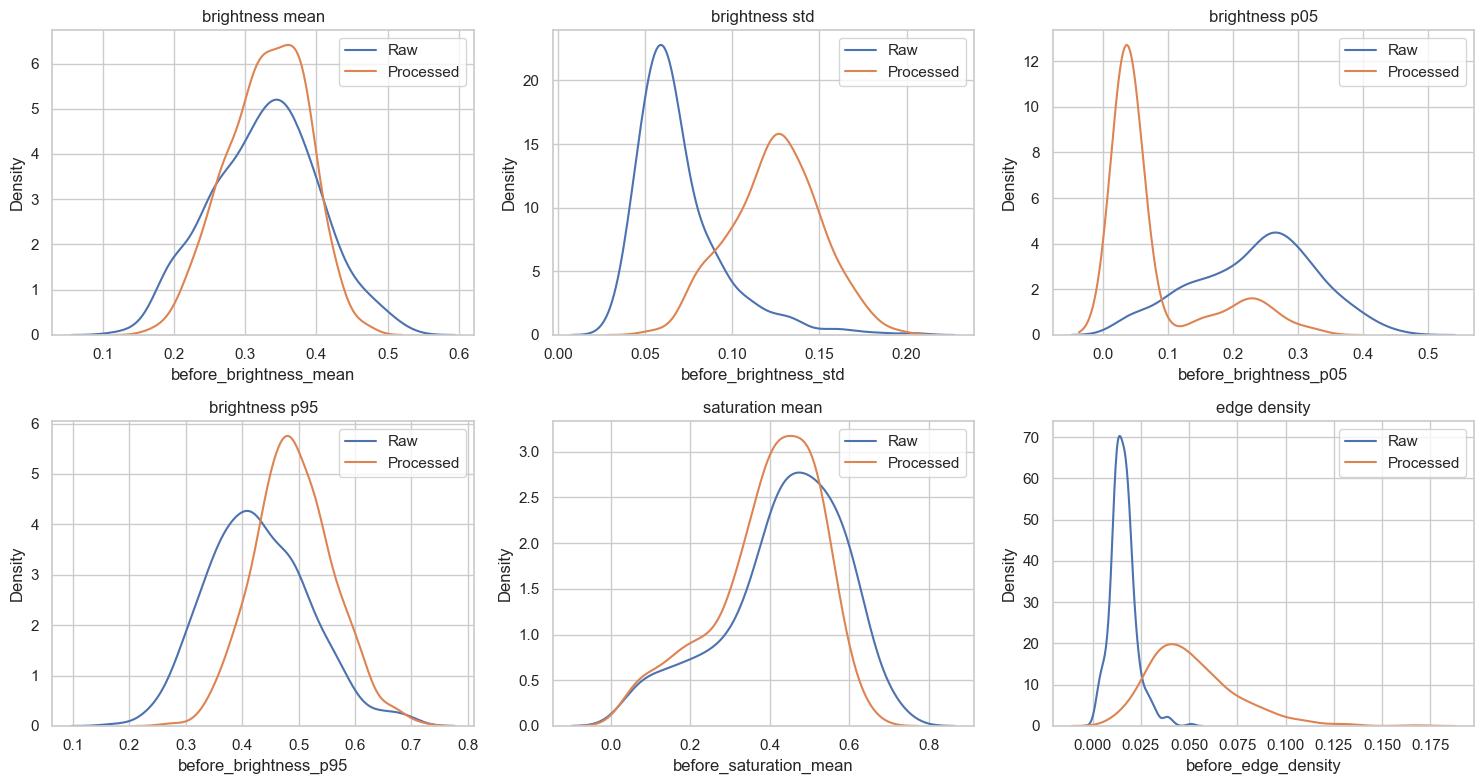

Saved graph: d:\omar\SIC\grad_project\artefacts\before_after_changes_by_grade.png


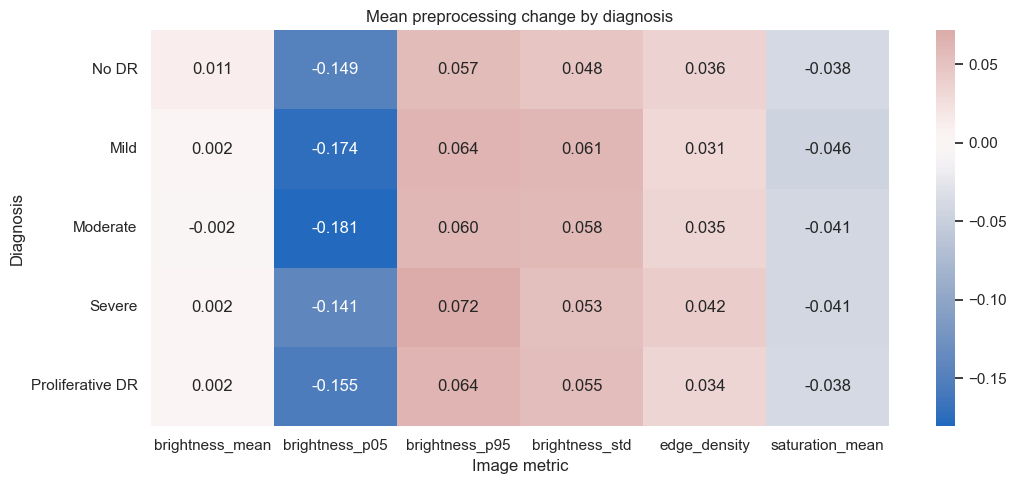

In [9]:
grade_rows = []
for grade, group in paired.groupby("before_diagnosis"):
    for metric in metric_cols:
        grade_rows.append({"diagnosis": int(grade), "metric": metric,
                           "before_mean": group[f"before_{metric}"].mean(),
                           "after_mean": group[f"after_{metric}"].mean(),
                           "mean_change": (group[f"after_{metric}"]-group[f"before_{metric}"]).mean()})
grade_comparison = pd.DataFrame(grade_rows)
display(grade_comparison.pivot(index="diagnosis", columns="metric", values=["before_mean", "after_mean", "mean_change"]).round(4))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, metric in zip(axes.flat, metric_cols):
    sns.kdeplot(paired[f"before_{metric}"], label="Raw", ax=ax)
    sns.kdeplot(paired[f"after_{metric}"], label="Processed", ax=ax)
    ax.set_title(metric.replace("_", " ")); ax.legend()
plt.tight_layout()
save_figure(fig, "before_after_metric_distributions.png")
plt.show()

change_table = grade_comparison.pivot(index="diagnosis", columns="metric", values="mean_change")
change_table.index = [CLASS_NAMES[int(i)] for i in change_table.index]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(change_table, annot=True, fmt=".3f", center=0, cmap="vlag", ax=ax)
ax.set(title="Mean preprocessing change by diagnosis", xlabel="Image metric", ylabel="Diagnosis")
plt.tight_layout()
save_figure(fig, "before_after_changes_by_grade.png")
plt.show()


### Graph indicating preprocessed img sizes

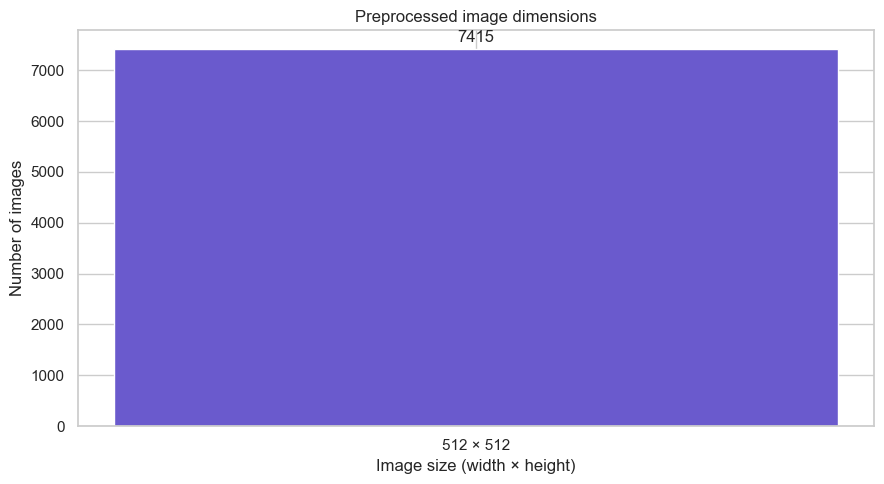

In [10]:

processed_sizes = []

for split in ["train", "validation", "test"]:
    image_dir = PROCESSED / split / "images"

    for path in image_dir.iterdir():
        if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            with Image.open(path) as image:
                processed_sizes.append((image.width, image.height))

size_counts = Counter(processed_sizes)
labels = [f"{width} × {height}" for width, height in size_counts]
counts = list(size_counts.values())

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(labels, counts, color="slateblue")
ax.set(
    title="Preprocessed image dimensions",
    xlabel="Image size (width × height)",
    ylabel="Number of images",
)
ax.bar_label(ax.containers[0], padding=3)
plt.xticks(rotation=0)
plt.tight_layout()

fig.savefig(
    ROOT / "artefacts" / "preprocessed_image_dimensions.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()